# Lab 2 - homework

## 1. Download data

In [2]:
%%bash
wget -q https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv -O data/tariff-distances-2022-01.csv
wget -q https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv -O data/stations-2023-09.csv

for year in $(seq 2011 2023); do
    wget -q https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-$year.csv -O data/disruptions-$year.csv
done

for year in $(seq 2019 2025); do
    wget -q https://opendata.rijdendetreinen.nl/public/services/services-$year.csv.gz -O data/services-$year.csv.gz
done

## 2. Stations table

In [1]:
import duckdb

db = duckdb.connect("data/homework.db")

db.sql("""
CREATE OR REPLACE TABLE stations AS
FROM 'data/stations-2023-09.csv'
""")
db.sql("DESCRIBE stations")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

## 3. Distances tables

In [2]:
db.sql("""
CREATE OR REPLACE TABLE distances AS
FROM read_csv('data/tariff-distances-2022-01.csv', nullstr = 'XXX')
""")

db.sql("""
CREATE OR REPLACE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance
""")

db.sql("FROM distances_long LIMIT 5")

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
│ AC      │ AHZ           │       90 │
│ AC      │ AKL           │       71 │
└─────────┴───────────────┴──────────┘

## 4. Disruptions table - Postgres

In [3]:
import os
from dotenv import load_dotenv

load_dotenv()
conn_string = f"host=localhost user={os.getenv('DB_USER')} password={os.getenv('DB_PASSWORD')} dbname=postgres"

db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db (TYPE postgres)
""")

db.sql("""
CREATE TABLE IF NOT EXISTS postgres_db.disruptions AS
FROM read_csv('data/disruptions-*.csv')
""")

db.sql("""
SELECT YEAR(start_time) AS year, COUNT(*) AS num_disruptions
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year
""")

┌───────┬─────────────────┐
│ year  │ num_disruptions │
│ int64 │      int64      │
├───────┼─────────────────┤
│  2011 │            1846 │
│  2012 │            2074 │
│  2013 │            2312 │
│  2014 │            2484 │
│  2015 │            2947 │
│  2016 │            3031 │
│  2017 │            4085 │
│  2018 │            5190 │
│  2019 │            5940 │
│  2020 │            4450 │
│  2021 │            4874 │
│  2022 │            5499 │
│  2023 │            5168 │
├───────┴─────────────────┤
│ 13 rows       2 columns │
└─────────────────────────┘

## 5. Services table - Parquet

In [4]:
db.sql("""
COPY (FROM read_csv('data/services-*.csv.gz'))
TO 'data/services.parquet' (FORMAT parquet, COMPRESSION zstd)
""")

db.sql("""
CREATE OR REPLACE TABLE services AS
FROM 'data/services.parquet'
""")

db.sql("""
SELECT YEAR("Service:Date") AS year, COUNT(*) AS num_rows
FROM services
GROUP BY year
ORDER BY year
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────┬──────────┐
│ year  │ num_rows │
│ int64 │  int64   │
├───────┼──────────┤
│  2019 │ 20773804 │
│  2020 │ 22235137 │
│  2021 │ 21818011 │
│  2022 │ 22025754 │
│  2023 │ 21239393 │
│  2024 │ 21857914 │
│  2025 │ 22226311 │
└───────┴──────────┘

## 7. Queries

### 1. How many trains departed from Amsterdam Central station overall?

In [5]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS num_trains
FROM services
WHERE "Stop:Station code" = 'ASD' AND "Stop:Departure time" IS NOT NULL
""")

┌────────────┐
│ num_trains │
│   int64    │
├────────────┤
│    1940873 │
└────────────┘

### 2. Calculate the average arrival delay of different service types (`Service:Type`). Order results descending by average delay.

In [6]:
db.sql("""
SELECT "Service:Type", AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
GROUP BY "Service:Type"
ORDER BY avg_arrival_delay DESC
""")

┌──────────────────────┬────────────────────┐
│     Service:Type     │ avg_arrival_delay  │
│       varchar        │       double       │
├──────────────────────┼────────────────────┤
│ Alpen Express        │  31.84254143646409 │
│ Krokus Express       │ 18.304347826086957 │
│ European Sleeper     │ 14.262589044460821 │
│ Nightjet             │   9.42391097403092 │
│ ICE                  │   7.76692176533566 │
│ Eurostar             │  7.302104678961749 │
│ ICE International    │  5.482790573052148 │
│ Thalys               │ 5.3961896909446025 │
│ Int. Trein           │  4.677560708417016 │
│ Nachttrein           │ 3.8370501214396113 │
│     ·                │                 ·  │
│     ·                │                 ·  │
│     ·                │                 ·  │
│ Snelbus i.p.v. trein │                0.0 │
│ Belbus ipv trein     │                0.0 │
│ Taxibus ipv trein    │                0.0 │
│ Niet instappen       │                0.0 │
│ Tram ipv trein       │          

### 3. What was the most common disruption cause in different years?

In [7]:
db.sql("""
SELECT YEAR(start_time) AS year, MODE(cause_en) AS most_common_cause
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year
""")

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
├───────┴───────────────────┤
│ 13 rows         2 columns │
└───────────────────────────┘

### 4. How many trains started their overall service in any Amsterdam station?

In [8]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS num_trains
FROM services
WHERE "Stop:Station name" LIKE 'Amsterdam%' AND "Stop:Arrival time" IS NULL
""")

┌────────────┐
│ num_trains │
│   int64    │
├────────────┤
│    1277350 │
└────────────┘

### 5. What fraction of services was run to final destinations outside the Netherlands?

In [9]:
db.sql("""
SELECT
    COUNT(DISTINCT s."Service:RDT-ID") FILTER (WHERE st.country <> 'NL')
    / COUNT(DISTINCT s."Service:RDT-ID") AS fraction_abroad
FROM services s
JOIN stations st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────┐
│   fraction_abroad    │
│        double        │
├──────────────────────┤
│ 0.037754095473173724 │
└──────────────────────┘

### 6. What is the largest distance between stations in the Netherlands (code `NL`)?

In [10]:
db.sql("""
SELECT s1.name_long AS station1, s2.name_long AS station2, d.distance
FROM distances_long d
JOIN stations s1 ON d.station = s1.code
JOIN stations s2 ON d.other_station = s2.code
WHERE s1.country = 'NL' AND s2.country = 'NL' AND d.station < d.other_station
ORDER BY d.distance DESC
LIMIT 1
""")

┌───────────┬────────────┬──────────┐
│ station1  │  station2  │ distance │
│  varchar  │  varchar   │  int64   │
├───────────┼────────────┼──────────┤
│ Eemshaven │ Vlissingen │      426 │
└───────────┴────────────┴──────────┘

### 7. Compare the average arrival delay between different train operators (`Service:Company`) on a bar plot. Sort them appropriately.

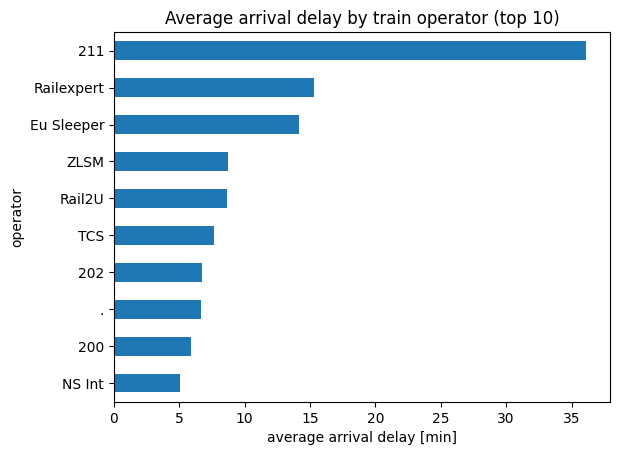

In [11]:
df_companies = db.sql("""
SELECT "Service:Company", AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
GROUP BY "Service:Company"
HAVING avg_arrival_delay > 0
ORDER BY avg_arrival_delay DESC
""").df()

df_companies.head(10).sort_values("avg_arrival_delay").plot.barh(
    x="Service:Company",
    y="avg_arrival_delay",
    legend=False,
    title="Average arrival delay by train operator (top 10)",
    xlabel="average arrival delay [min]",
    ylabel="operator",
);

### 8. How many services were disrupted in different years? Make a line plot.

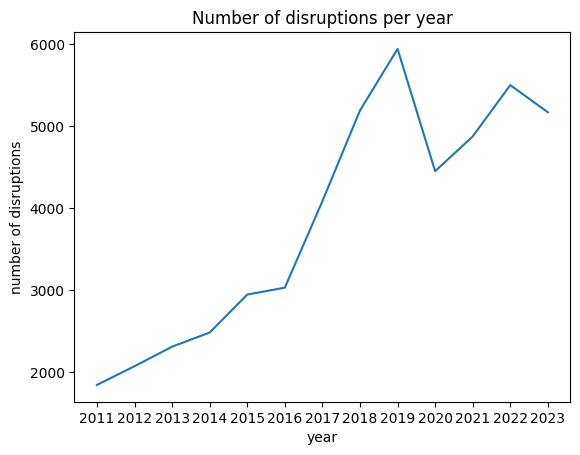

In [12]:
df_disrupted = db.sql("""
SELECT YEAR(start_time) AS year, COUNT(*) AS num_disruptions
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year
""").df()

df_disrupted.plot(
    x="year",
    y="num_disruptions",
    legend=False,
    xticks=df_disrupted["year"],
    title="Number of disruptions per year",
    xlabel="year",
    ylabel="number of disruptions",
);

### 9. What fraction of all services were cancelled (`Service:Completely cancelled`) in different years? Make a line plot.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

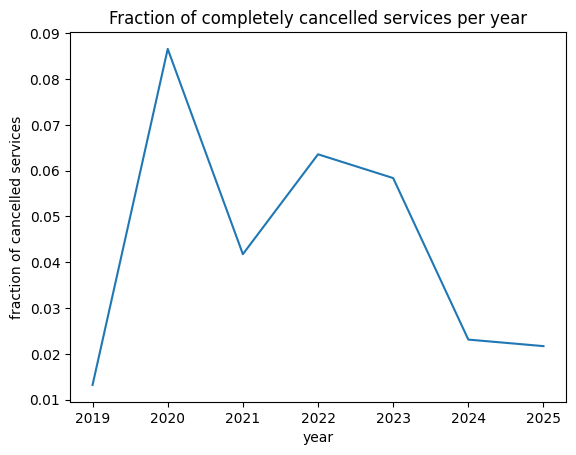

In [13]:
df_cancelled = db.sql("""
SELECT
    YEAR("Service:Date") AS year,
    COUNT(DISTINCT "Service:RDT-ID") FILTER (WHERE "Service:Completely cancelled")
    / COUNT(DISTINCT "Service:RDT-ID") AS fraction_cancelled
FROM services
GROUP BY year
ORDER BY year
""").df()

df_cancelled.plot(
    x="year",
    y="fraction_cancelled",
    legend=False,
    xticks=df_cancelled["year"],
    title="Fraction of completely cancelled services per year",
    xlabel="year",
    ylabel="fraction of cancelled services",
);

## 8. Station connections

In [14]:
db.sql("""
CREATE OR REPLACE TABLE station_connections AS
WITH connections AS (
    SELECT
        "Service:RDT-ID",
        "Stop:Station code" AS start_station_code,
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time"
        ) AS end_station_code
    FROM services
),
pairs AS (
    SELECT MIN("Service:RDT-ID") AS "Service:RDT-ID", start_station_code, end_station_code
    FROM connections
    WHERE end_station_code IS NOT NULL
    GROUP BY start_station_code, end_station_code
)
SELECT p.*, d.distance
FROM pairs p
LEFT JOIN distances_long d
    ON p.start_station_code = d.station AND p.end_station_code = d.other_station
""")

db.sql("SELECT * FROM station_connections LIMIT 5")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│         738959 │ HGZ                │ MTH              │        2 │
│         738959 │ MTH                │ KW               │        1 │
│         738816 │ UT                 │ UTO              │        3 │
│         739127 │ ST                 │ SD               │        1 │
│         738964 │ RV                 │ SM               │        6 │
└────────────────┴────────────────────┴──────────────────┴──────────┘

### 3. What is the largest distance between a pair of stations?

In [15]:
db.sql("""
SELECT start_station_code, end_station_code, distance
FROM station_connections
ORDER BY distance DESC
LIMIT 1
""")

┌────────────────────┬──────────────────┬──────────┐
│ start_station_code │ end_station_code │ distance │
│      varchar       │     varchar      │  int64   │
├────────────────────┼──────────────────┼──────────┤
│ VS                 │ STV              │      421 │
└────────────────────┴──────────────────┴──────────┘

### 4. Plot a histogram of inter-station distances run by trains.

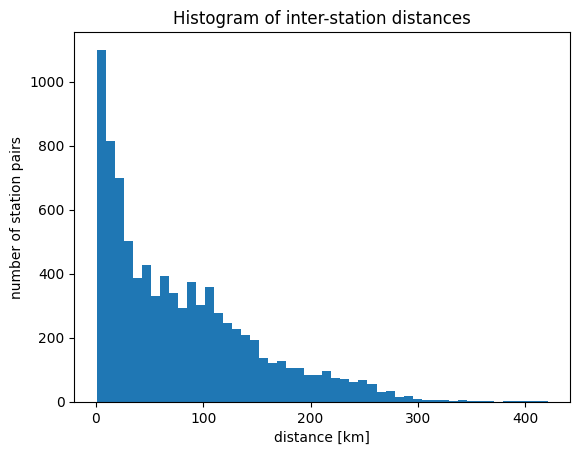

In [16]:
df_connections = db.sql("""
SELECT distance
FROM station_connections
WHERE distance IS NOT NULL
""").df()

df_connections.plot.hist(
    bins=50,
    legend=False,
    title="Histogram of inter-station distances",
    xlabel="distance [km]",
    ylabel="number of station pairs",
);

In [17]:
db.sql("""
SELECT "Stop:Station code", "Stop:Arrival time", "Stop:Departure time"
FROM services
WHERE "Service:RDT-ID" = (
    SELECT "Service:RDT-ID" FROM station_connections
    WHERE start_station_code = 'VS' AND end_station_code = 'STV'
)
""")

┌───────────────────┬─────────────────────┬─────────────────────┐
│ Stop:Station code │  Stop:Arrival time  │ Stop:Departure time │
│      varchar      │      timestamp      │      timestamp      │
├───────────────────┼─────────────────────┼─────────────────────┤
│ GS                │ NULL                │ 2021-09-03 12:40:00 │
│ SK                │ NULL                │ 2021-09-03 12:47:00 │
│ MDB               │ 2021-09-03 13:05:00 │ 2021-09-03 13:08:00 │
│ WK                │ 2021-09-03 13:10:00 │ 2021-09-03 13:10:00 │
│ VSS               │ 2021-09-03 13:15:00 │ 2021-09-03 13:15:00 │
│ HNP               │ 2021-09-03 13:15:00 │ 2021-09-03 13:15:00 │
│ VS                │ 2021-09-03 13:23:00 │ NULL                │
│ KMW               │ 2021-09-03 13:30:00 │ 2021-09-03 13:30:00 │
│ STV               │ 2021-09-03 13:38:00 │ NULL                │
└───────────────────┴─────────────────────┴─────────────────────┘